# Manufacturing Quality & Defect Analysis

This project looks at production data from a semiconductor factory (UCI SECOM dataset) to find when and why units fail.

**Data:** 1,567 production units, each with 590 sensor readings, a pass/fail result and a timestamp (19 Jul to 17 Oct 2008). 104 units failed (6.6%).

**Goal:** Find out when failures happen (by shift and by week) which sensors behave differently on failed units and how well failures can be predicted.

**Tools:** Python (pandas, NumPy, SciPy, scikit-learn, Matplotlib) and Power BI.

## Setup

Importing the libraries used in this notebook.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, cross_val_predict
from sklearn.pipeline import Pipeline

## Data Loading

The data comes in two files without headers: `secom.data` has 590 sensor readings per unit and `secom_labels.data` has the pass/fail label and timestamp. The sensors are named `sensor_0` to `sensor_589` because the real names are not shared. The two files are joined and a new `Fail` column is created (1 = fail, 0 = pass).

The checks below show 1,567 units, 104 failures, a 3-month date range and 41,951 missing sensor readings. Missing values are normal for this dataset.

In [5]:
data = pd.read_csv("../data/secom.data", sep=r"\s+", header=None)
data.columns = [f"sensor_{i}" for i in range(data.shape[1])]

In [6]:
labels = pd.read_csv("../data/secom_labels.data", sep=" ", header=None,
                     names=["label", "timestamp"], quotechar='"')
labels["timestamp"] = pd.to_datetime(labels["timestamp"], format="%d/%m/%Y %H:%M:%S")

In [7]:
df = pd.concat([data, labels], axis=1)
df["Fail"] = (df["label"] == 1).astype(int)

In [8]:
print(df.shape)                    
print(df["Fail"].value_counts())   
print(df["timestamp"].min(), df["timestamp"].max())
print(df.isna().sum().sum())       

(1567, 593)
Fail
0    1463
1     104
Name: count, dtype: int64
2008-07-19 11:55:00 2008-10-17 06:07:00
41951


## Data Cleaning

Some sensors are not useful. I removed sensors with more than 40% missing values (32 sensors) and sensors with the same value in every row (116 sensors). That leaves 442 sensors.

The cleaned table is sorted by time. The remaining missing values are filled with the median of each sensor. The prediction models later do their own filling inside a pipeline, so test data is not used to fill values.

In [10]:
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]

missing_pct = df[sensor_cols].isna().mean() * 100
print((missing_pct > 40).sum(), "sensors have >40% missing")

nunique = df[sensor_cols].nunique()
print((nunique <= 1).sum(), "sensors are constant")

keep = [c for c in sensor_cols if missing_pct[c] <= 40 and nunique[c] > 1]
print(len(keep), "sensors kept out of", len(sensor_cols))

32 sensors have >40% missing
116 sensors are constant
442 sensors kept out of 590


In [11]:
clean = df[["timestamp", "Fail"] + keep].copy()
clean = clean.sort_values("timestamp").reset_index(drop=True)

clean[keep] = clean[keep].fillna(clean[keep].median())
print(clean.isna().sum().sum())   

0


## Time Features & Shifts

I created date, hour, weekday and week columns from the timestamp. Each unit is also given a shift: Morning (6-14), Evening (14-22) or Night (22-6). The dataset does not say what the real shifts are, so these hours are my assumption.

In [13]:
def get_shift(h):
    if 6 <= h < 14:
        return "Morning (6-14)"
    elif 14 <= h < 22:
        return "Evening (14-22)"
    else:
        return "Night (22-6)"

clean = clean.assign(
    date=clean["timestamp"].dt.date,
    hour=clean["timestamp"].dt.hour,
    weekday=clean["timestamp"].dt.day_name(),
    week=clean["timestamp"].dt.isocalendar().week,
)
clean["shift"] = clean["hour"].apply(get_shift)

## Failure Patterns by Shift and Week

Here I check how the failure rate changes by shift and by week. A chi-square test shows whether the difference between shifts is real or just chance.

In [15]:
print(clean.groupby("shift")["Fail"].agg(["count", "sum", "mean"]))
print(clean.groupby("week")["Fail"].agg(["count", "sum", "mean"]))

                 count  sum      mean
shift                                
Evening (14-22)    568   40  0.070423
Morning (6-14)     492   31  0.063008
Night (22-6)       507   33  0.065089
      count  sum      mean
week                      
29       13    3  0.230769
30       21    2  0.095238
31       48   10  0.208333
32      108   14  0.129630
33       51    7  0.137255
34      208   22  0.105769
35      169    7  0.041420
36      133    2  0.015038
37       95    4  0.042105
38      154    5  0.032468
39      166    4  0.024096
40      169   15  0.088757
41      138    8  0.057971
42       94    1  0.010638


In [16]:
ct = pd.crosstab(clean["shift"], clean["Fail"])
chi2, p_shift, dof, exp = chi2_contingency(ct)
print(f"chi-square p-value: {p_shift:.3f}")

chi-square p-value: 0.881


The failure rate is almost the same in all three shifts (6.3% to 7.0%). The chi-square p-value is 0.881 which is much higher than 0.05 there is no evidence that shift affects failures in this data.

The weekly rate changes much more. It is high in the first weeks and lower from week 35. Weeks 29, 30 and 31 have very few units (13, 21 and 48) so their rates are not very reliable.

In [18]:
# Weekly failure rate
wk = clean.groupby("week")["Fail"].agg(n="count", fails="sum").reset_index()
wk["p"] = wk["fails"] / wk["n"]
pbar = wk["fails"].sum() / wk["n"].sum()

# Control limits (they change each week because n changes)
wk["UCL"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / wk["n"])
wk["LCL"] = (pbar - 3 * np.sqrt(pbar * (1 - pbar) / wk["n"])).clip(lower=0)
wk["out"] = (wk["p"] > wk["UCL"]) | (wk["p"] < wk["LCL"])

# Extra columns used later in Power BI
wk["pbar"] = pbar
wk["p_out"] = wk["p"].where(wk["out"])

## Process Monitoring: Weekly p-chart

A p-chart tracks the share of failed units each week. The centre line is the overall failure rate (6.6%). The upper and lower limits are set 3 standard deviations from the centre line. A week above the upper limit has more failures than normal variation would explain. The limits move from week to week because the number of units is different each week.

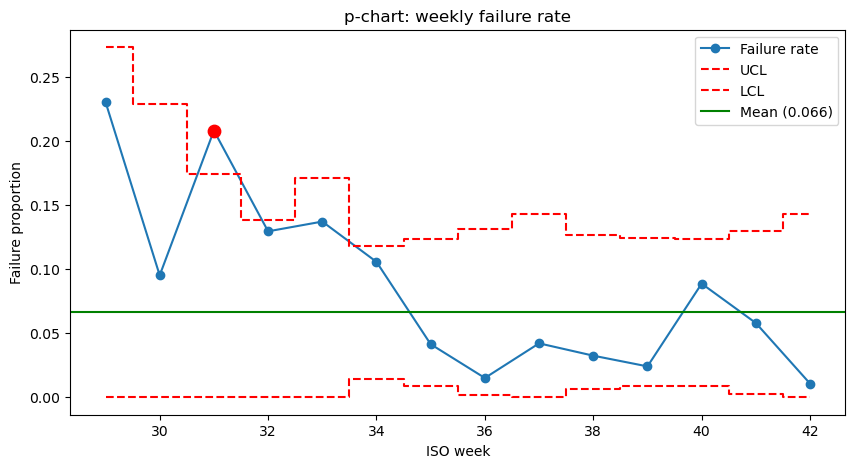

   week   n  fails         p       UCL  LCL   out      pbar     p_out
2    31  48     10  0.208333  0.174157  0.0  True  0.066369  0.208333


In [20]:
plt.figure(figsize=(10, 5))
plt.plot(wk["week"], wk["p"], marker="o", label="Failure rate")
plt.step(wk["week"], wk["UCL"], where="mid", color="red", linestyle="--", label="UCL")
plt.step(wk["week"], wk["LCL"], where="mid", color="red", linestyle="--", label="LCL")
plt.axhline(pbar, color="green", label=f"Mean ({pbar:.3f})")
plt.scatter(wk.loc[wk["out"], "week"], wk.loc[wk["out"], "p"], color="red", zorder=5, s=80)
plt.xlabel("ISO week"); plt.ylabel("Failure proportion"); plt.title("p-chart: weekly failure rate")
plt.legend(); plt.show()

print(wk[wk["out"]])

Only week 31 is out of control: 10 failures in 48 units (20.8%) above the upper limit of 17.4%.

Weeks 29 to 34 are all above the average rate. From week 35 the rate is mostly below average, with week 40 as the one exception. This suggests the process changed around week 34 or 35. The data does not show the reason.

## Sensor Analysis

Next I look at which sensors behave differently on failed units and whether a control chart on a single sensor can catch failures.

### Ranking sensors

For each of the 442 sensors, a Mann-Whitney test compares the readings of failed units with the readings of passed units. A small p-value means the two groups look different. I used this test because sensor readings are not normally distributed.

In [24]:
res = []
for c in keep:
    a = clean.loc[clean["Fail"] == 1, c]
    b = clean.loc[clean["Fail"] == 0, c]
    stat, p = mannwhitneyu(a, b, alternative="two-sided")
    res.append((c, p))

rank = pd.DataFrame(res, columns=["sensor", "p_value"]).sort_values("p_value")
top_sensors = rank.head(5)["sensor"].tolist()
print(rank.head(10))

         sensor       p_value
54    sensor_59  5.181701e-11
93   sensor_103  9.434706e-09
385  sensor_510  3.420323e-06
364  sensor_477  3.442858e-05
115  sensor_129  4.644758e-05
178  sensor_205  4.662632e-05
26    sensor_28  7.445539e-05
31    sensor_33  1.615225e-04
270  sensor_341  1.859234e-04
252  sensor_316  1.901966e-04


sensor_59 and sensor_103 stand out the most. Because I tested 442 sensors a few will look different just by chance. A stricter cutoff is 0.05 / 442 ≈ 0.0001. The top 7 sensors pass this cutoff and sensor_33 and the ones below it do not. I treat this list as a shortlist, not proof.

### Control charts for the top sensors

An I-MR chart tracks one sensor over time. The centre line is the average and the red lines are 3 standard deviations away (estimated from the moving range). Red dots are readings outside the limits and black crosses are failed units.

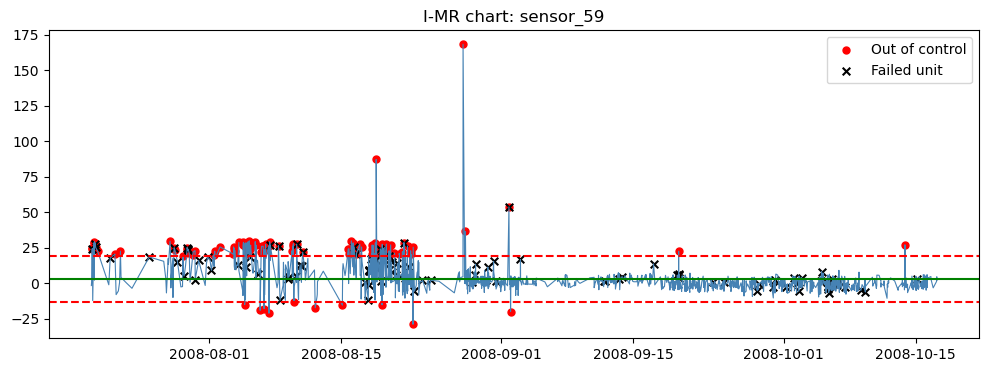

sensor_59 | out-of-control points: 130 | failure rate when OOC: 0.138 | baseline: 0.066


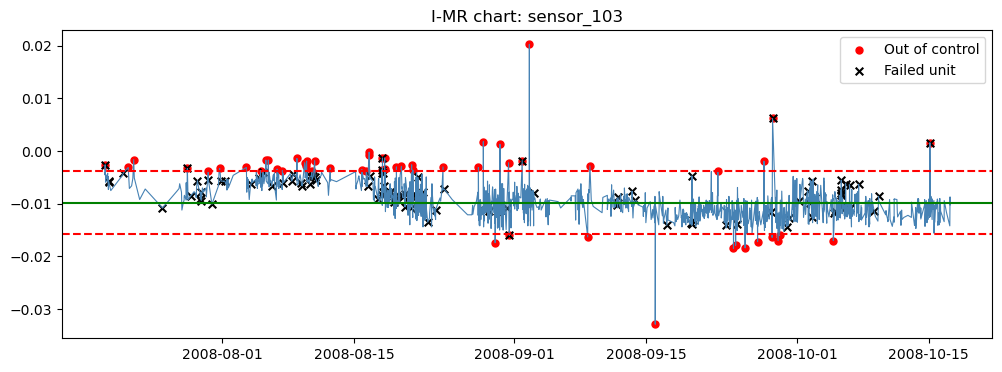

sensor_103 | out-of-control points: 56 | failure rate when OOC: 0.143 | baseline: 0.066


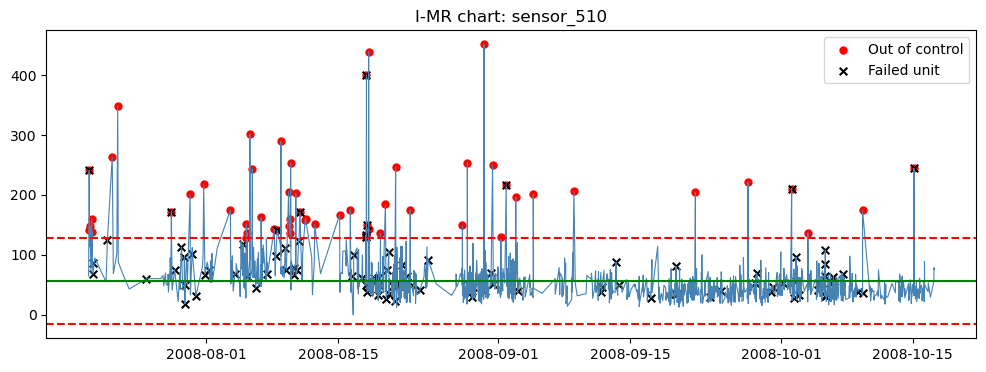

sensor_510 | out-of-control points: 57 | failure rate when OOC: 0.193 | baseline: 0.066


In [27]:
def imr_chart(col):
    x = clean[col].values
    mr = np.abs(np.diff(x))
    sigma = mr.mean() / 1.128            
    cl = x.mean()
    ucl, lcl = cl + 3 * sigma, cl - 3 * sigma
    ooc = (x > ucl) | (x < lcl)

    plt.figure(figsize=(12, 4))
    plt.plot(clean["timestamp"], x, lw=0.8, color="steelblue")
    plt.axhline(cl, color="green"); plt.axhline(ucl, color="red", ls="--"); plt.axhline(lcl, color="red", ls="--")
    plt.scatter(clean["timestamp"][ooc], x[ooc], color="red", s=25, label="Out of control")
    f = clean["Fail"].values == 1
    plt.scatter(clean["timestamp"][f], x[f], marker="x", color="black", s=30, label="Failed unit")
    plt.title(f"I-MR chart: {col}"); plt.legend(); plt.show()

    print(col, "| out-of-control points:", ooc.sum(),
          "| failure rate when OOC:", round(clean["Fail"].values[ooc].mean(), 3) if ooc.sum() else "n/a",
          "| baseline:", round(clean["Fail"].mean(), 3))

for s in top_sensors[:3]:
    imr_chart(s)

When a sensor goes out of control the failure rate is about 2 to 3 times higher than the normal 6.6%:

- sensor_59: 13.8% (130 out-of-control points)
- sensor_103: 14.3% (56 points)
- sensor_510: 19.3% (57 points)

But most failed units (black crosses) are inside the limits so these sensors only give a warning sign, not a reliable detector. sensor_59 is also very unstable until late August and calm after that which matches the drop in failures in the p-chart.

### How many failures do the charts catch?

For each of the top 10 sensors I count the out-of-control points and how many of them were real failures. Precision is the share of out-of-control points that were failures. Recall is the share of all failures that were caught. Lift is precision divided by the normal failure rate (6.6%) so a lift of 2 means twice as many failures as normal. I also test a combined rule that flags a unit if any of the top 5 sensors is out of control.

In [30]:
def ooc_stats(col):
    x = clean[col].values
    sigma = np.abs(np.diff(x)).mean() / 1.128
    cl = x.mean()
    ooc = (x > cl + 3*sigma) | (x < cl - 3*sigma)
    fails = clean["Fail"].values == 1
    caught = (ooc & fails).sum()
    return {"sensor": col, "ooc_points": ooc.sum(), "fails_caught": caught,
            "precision": caught / ooc.sum() if ooc.sum() else np.nan,
            "recall": caught / fails.sum(),
            "lift": (caught / ooc.sum()) / fails.mean() if ooc.sum() else np.nan}, ooc

top10 = rank.head(10)["sensor"].tolist()
rows, flags = [], []
for s in top10:
    r, o = ooc_stats(s); rows.append(r); flags.append(o)

print(pd.DataFrame(rows).round(3))

any_ooc = np.any(flags[:5], axis=0)
fails = clean["Fail"].values == 1
print("Combined top-5 rule -> flagged:", any_ooc.sum(),
      "| fails caught:", (any_ooc & fails).sum(),
      "| recall:", round((any_ooc & fails).sum() / fails.sum(), 3),
      "| precision:", round((any_ooc & fails).sum() / any_ooc.sum(), 3))

       sensor  ooc_points  fails_caught  precision  recall   lift
0   sensor_59         130            18      0.138   0.173  2.086
1  sensor_103          56             8      0.143   0.077  2.152
2  sensor_510          57            11      0.193   0.106  2.908
3  sensor_477          18             1      0.056   0.010  0.837
4  sensor_129         329            13      0.040   0.125  0.595
5  sensor_205          21             2      0.095   0.019  1.435
6   sensor_28          36             3      0.083   0.029  1.256
7   sensor_33          24             3      0.125   0.029  1.883
8  sensor_341          16             3      0.188   0.029  2.825
9  sensor_316          31             1      0.032   0.010  0.486
Combined top-5 rule -> flagged: 512 | fails caught: 38 | recall: 0.365 | precision: 0.074


Some sensors have a useful lift (sensor_510 at 2.9, sensor_103 at 2.2, sensor_59 at 2.1) but each one catches only 8 to 17% of the failures. sensor_129 has a lift below 1 so its out-of-control readings are not linked to failures.

The combined rule flags 512 units (about a third of all production) and catches 38 of the 104 failures. Its precision is 7.4% only slightly above the normal 6.6%. So control charts on single sensors are not good enough to find failed units. The sensors were picked using the failure labels so these numbers are a bit too good.

### Does sensor_59 variation follow the failure rate?

sensor_59 was very unstable early on when failure rates were also high. To check this I compare the weekly standard deviation of sensor_59 with the weekly failure rate. Weeks 29 and 30 are left out because they have fewer than 30 units.

In [33]:
w = clean.groupby("week").agg(n=("Fail", "count"), fail_rate=("Fail", "mean"),
                              s59_std=("sensor_59", "std")).reset_index()
w = w[w["n"] >= 30]         
print(w.round(3))
print(spearmanr(w["s59_std"], w["fail_rate"]))

    week    n  fail_rate  s59_std
2     31   48      0.208    8.804
3     32  108      0.130   14.236
4     33   51      0.137   11.838
5     34  208      0.106   11.276
6     35  169      0.041   13.599
7     36  133      0.015    5.744
8     37   95      0.042    2.726
9     38  154      0.032    3.915
10    39  166      0.024    2.784
11    40  169      0.089    3.472
12    41  138      0.058    3.332
13    42   94      0.011    4.215
SignificanceResult(statistic=0.41958041958041964, pvalue=0.1745190081300594)


Both are lower from week 36 onward and the correlation is 0.42. But the p-value is 0.17 and there are only 12 weeks so this could be a coincidence. It is a possible link, not a proven one.

## Anomaly Detection

An Isolation Forest finds units that look unusual compared with the rest of the production. It does not use the pass/fail label to learn, so it shows whether failed units look different on their own. Each unit gets an anomaly score (higher means more unusual). I set the share of flagged units to 6.6% which is the normal failure rate.

In [36]:
Xc = clean[keep]
iso = IsolationForest(n_estimators=300, contamination=0.066, random_state=42)
iso.fit(Xc)

clean = clean.copy()
clean = clean.assign(
    anomaly_score=-iso.score_samples(Xc),             
    iso_flag=(iso.predict(Xc) == -1).astype(int),
)

### How well does it find failures?

Two scores check whether failed units get higher anomaly scores than passed units. ROC-AUC of 0.5 means no better than chance. PR-AUC is compared with the normal failure rate (0.066). Then I count how many of the flagged units were real failures.

In [38]:
y_true = clean["Fail"]

print("ROC-AUC:", round(roc_auc_score(y_true, clean["anomaly_score"]), 3))
print("PR-AUC :", round(average_precision_score(y_true, clean["anomaly_score"]), 3),
      "(baseline = 0.066)")

tp = ((clean["iso_flag"] == 1) & (y_true == 1)).sum()
print("Flagged:", clean["iso_flag"].sum(), "| fails caught:", tp,
      "| precision:", round(tp / clean["iso_flag"].sum(), 3),
      "| recall:", round(tp / y_true.sum(), 3))

ROC-AUC: 0.578
PR-AUC : 0.114 (baseline = 0.066)
Flagged: 104 | fails caught: 14 | precision: 0.135 | recall: 0.135


The scores are only a little better than chance: ROC-AUC is 0.578 and PR-AUC is 0.114 (the baseline is 0.066). The model flagged 104 units and 14 of them were real failures. That is a precision of 13.5% about twice the normal rate but it still misses 86% of the failures.

So failed units are only slightly different from passed units in this data. Without using the labels, anomaly detection is not a strong way to find failures here.

## Predictive Modeling

Here I test whether failures can be predicted from the sensor readings, using a Random Forest. Because the data is ordered in time I test the model in three ways from easiest to strictest. The score changes a lot between them which is the main result of this section.

### Step 1: Shuffled cross-validation

Units are split randomly into 5 groups. The model trains on 4 groups and predicts the 5th and this repeats until every unit has a prediction. Missing values are filled inside the pipeline, so the filling only uses training data. The failure class is small so the model uses balanced class weights. Then I check what happens if only the 10% of units with the highest risk score are inspected.

In [42]:
X = df[keep]
y = df["Fail"]

pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                  class_weight="balanced_subsample",
                                  random_state=42, n_jobs=-1)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]

print("ROC-AUC:", round(roc_auc_score(y, proba), 3))
print("PR-AUC :", round(average_precision_score(y, proba), 3), "(baseline = 0.066)")

# Inspect only the 10% of units with the highest risk
thr = np.quantile(proba, 0.90)
top10_flag = proba >= thr
print("Top-10% flagged:", top10_flag.sum(),
      "| fails caught:", int((top10_flag & (y == 1)).sum()),
      "| precision:", round((top10_flag & (y == 1)).sum() / top10_flag.sum(), 3),
      "| recall:", round((top10_flag & (y == 1)).sum() / y.sum(), 3))

ROC-AUC: 0.716
PR-AUC : 0.151 (baseline = 0.066)
Top-10% flagged: 157 | fails caught: 26 | precision: 0.166 | recall: 0.25


This looks fairly good. ROC-AUC is 0.716 and PR-AUC is 0.151 (the baseline is 0.066). If only the top 10% riskiest units (157) are inspected, 26 of the 104 failures are found. That is a precision of 16.6% about 2.5 times the normal rate.

But this score is probably too high. The units are mixed randomly so the model is tested on units from the same weeks it learned from. The next steps test this.

### Which sensors matter most?

The Random Forest gives each sensor an importance score. This is based on a model fitted on all the data so it only shows which sensors the model uses, not how well it predicts.

In [45]:
pipe.fit(X, y)
imp = pd.Series(pipe.named_steps["rf"].feature_importances_, index=keep).sort_values(ascending=False)
print(imp.head(10))

sensor_59     0.022294
sensor_103    0.013383
sensor_33     0.012314
sensor_130    0.011640
sensor_205    0.007627
sensor_129    0.007509
sensor_477    0.007444
sensor_64     0.007143
sensor_19     0.006980
sensor_21     0.006835
dtype: float64


sensor_59 and sensor_103 are at the top, the same as in the Mann-Whitney ranking. The scores are small and spread over many sensors (the highest is only 0.022) so no single sensor drives the prediction.

### Step 2: Train on the past, test on the future

In a real factory a model can only learn from earlier units and must predict later ones. So I train on the first 70% of the units (by time) and test on the last 30%.

In [48]:
order = df.sort_values("timestamp").reset_index(drop=True)
split = int(len(order) * 0.7)

Xtr, ytr = order.loc[:split-1, keep], order.loc[:split-1, "Fail"]
Xte, yte = order.loc[split:, keep], order.loc[split:, "Fail"]

pipe.fit(Xtr, ytr)
p_te = pipe.predict_proba(Xte)[:, 1]
print("Test period fail rate:", round(yte.mean(), 3))
print("ROC-AUC:", round(roc_auc_score(yte, p_te), 3))
print("PR-AUC :", round(average_precision_score(yte, p_te), 3),
      "(baseline =", round(yte.mean(), 3), ")")

Test period fail rate: 0.055
ROC-AUC: 0.564
PR-AUC : 0.064 (baseline = 0.055 )


The score drops a lot. ROC-AUC is 0.564 (0.5 is chance) and PR-AUC is 0.064 against a baseline of 0.055. The model is almost no better than guessing on later data. One reason may be that the process changed around week 34 or 35 so what the model learned early on does not apply later. The test set is small (about 26 failures) so this one result is noisy. The next step checks it across several time windows.

### Step 3: Rolling validation

One time split can be lucky or unlucky so I repeat it 5 times. Each round trains on all earlier units and tests on the next block of 261 units. The first block is only used for training so predictions are made for the remaining 1,305 units.

In [51]:
Xo, yo = order[keep], order["Fail"]

tscv = TimeSeriesSplit(n_splits=5)
oot = np.full(len(order), np.nan)
for fold, (tr, te) in enumerate(tscv.split(Xo), 1):
    pipe.fit(Xo.iloc[tr], yo.iloc[tr])
    p = pipe.predict_proba(Xo.iloc[te])[:, 1]
    oot[te] = p
    print(f"Fold {fold}: test n={len(te)}, fail rate={yo.iloc[te].mean():.3f}, "
          f"ROC-AUC={roc_auc_score(yo.iloc[te], p):.3f}, "
          f"PR-AUC={average_precision_score(yo.iloc[te], p):.3f}")

mask = ~np.isnan(oot)
print("Pooled out-of-time ROC-AUC:", round(roc_auc_score(yo[mask], oot[mask]), 3))
print("Pooled out-of-time PR-AUC :", round(average_precision_score(yo[mask], oot[mask]), 3),
      "(baseline =", round(yo[mask].mean(), 3), ")")

Fold 1: test n=261, fail rate=0.084, ROC-AUC=0.546, PR-AUC=0.155
Fold 2: test n=261, fail rate=0.023, ROC-AUC=0.571, PR-AUC=0.030
Fold 3: test n=261, fail rate=0.038, ROC-AUC=0.635, PR-AUC=0.197
Fold 4: test n=261, fail rate=0.050, ROC-AUC=0.534, PR-AUC=0.055
Fold 5: test n=261, fail rate=0.054, ROC-AUC=0.610, PR-AUC=0.095
Pooled out-of-time ROC-AUC: 0.566
Pooled out-of-time PR-AUC : 0.087 (baseline = 0.05 )


ROC-AUC is above 0.5 in all 5 rounds (0.53 to 0.64) so the model does have a small real signal. The pooled scores are ROC-AUC 0.566 and PR-AUC 0.087 against a baseline of 0.050. That is much lower than the shuffled result (0.716 and 0.151). Each round has only about 6 to 22 failures so single-round scores such as the 0.197 in round 3, should not be trusted on their own.

### Risk groups on future data

Using the out-of-time predictions the 1,305 units are split into 5 equal groups from lowest risk (1) to highest risk (5). If the model works the failure rate should go up from group 1 to group 5.

In [54]:
oot_df = order.loc[mask, ["timestamp", "Fail"]].copy()
oot_df["oot_risk"] = oot[mask]
oot_df["risk_quintile"] = pd.qcut(oot_df["oot_risk"].rank(method="first"), 5,
                                  labels=[1, 2, 3, 4, 5]).astype(int)

q = oot_df.groupby("risk_quintile")["Fail"].agg(units="count", fails="sum", fail_rate="mean").reset_index()
q["lift_vs_overall"] = q["fail_rate"] / oot_df["Fail"].mean()
print(q.round(3))
print("Overall out-of-time fail rate:", round(oot_df["Fail"].mean(), 3))

top_q = oot_df["risk_quintile"] == 5
print("Top 20% riskiest: precision", round(oot_df.loc[top_q, "Fail"].mean(), 3),
      "| share of failures caught:", round(oot_df.loc[top_q, "Fail"].sum() / oot_df["Fail"].sum(), 3))

   risk_quintile  units  fails  fail_rate  lift_vs_overall
0              1    261     11      0.042            0.846
1              2    261     14      0.054            1.077
2              3    261      7      0.027            0.538
3              4    261     14      0.054            1.077
4              5    261     19      0.073            1.462
Overall out-of-time fail rate: 0.05
Top 20% riskiest: precision 0.073 | share of failures caught: 0.292


The highest-risk group has the highest failure rate (7.3% against 5.0% overall) and holds 19 of the 65 failures (29%). But the pattern is not steady: group 3 has the lowest rate (2.7%) and groups 2 and 4 are equal. With so few failures this is a weak result and could partly be chance.

## Export for Power BI

The results are saved as one Excel workbook (`powerbi_tables.xlsx`, one sheet per table) for the Power BI dashboard.

In [57]:
os.makedirs("../outputs", exist_ok=True)

# Unit-level table
top_sensors_export = ["sensor_59", "sensor_103", "sensor_510", "sensor_33", "sensor_130"]
units = clean[["timestamp", "date", "week", "weekday", "hour", "shift", "Fail",
               "anomaly_score", "iso_flag"] + top_sensors_export]

# Shift summary
shift_summary = (clean.groupby("shift")["Fail"]
                 .agg(units="count", fails="sum", fail_rate="mean").reset_index())

# Top 15 sensors by importance
feature_importance = imp.head(15).rename("importance").reset_index().rename(columns={"index": "sensor"})

# Save all tables as one Excel workbook (one sheet per table)
with pd.ExcelWriter("../outputs/powerbi_tables.xlsx") as writer:
    units.to_excel(writer, sheet_name="units", index=False)
    wk.to_excel(writer, sheet_name="weekly_pchart", index=False)
    shift_summary.to_excel(writer, sheet_name="shift_summary", index=False)
    pd.DataFrame(rows).to_excel(writer, sheet_name="sensor_ooc_stats", index=False)
    feature_importance.to_excel(writer, sheet_name="feature_importance", index=False)
    q.to_excel(writer, sheet_name="risk_quintiles_oot", index=False)
    oot_df.to_excel(writer, sheet_name="units_oot_scores", index=False)

print(os.listdir("powerbi_data"))

['powerbi_tables.xlsx']


## Summary & Key Findings

- Looked at 1,567 production units from the UCI SECOM dataset. 104 failed (6.6%). After removing empty and constant sensors, 442 sensors were used.
- Shift does not matter. The failure rate is 6.3% to 7.0% across the three shifts (chi-square p = 0.88). The shift hours are my own assumption.
- The weekly p-chart shows one out-of-control week (week 31, 20.8% failures). The failure rate is mostly above average until week 34 and mostly below average from week 35. The data does not explain why.
- sensor_59, sensor_103 and sensor_510 are the sensors most linked to failures. When they go out of control, the failure rate is 2 to 3 times higher but each catches only 8 to 17% of failures.
- Anomaly detection (Isolation Forest) is only a little better than chance (ROC-AUC 0.58).
- The Random Forest looked good with shuffled cross-validation (ROC-AUC 0.72) but fell to 0.57 when tested on future data. Testing on time-ordered data gives a more honest result.
- On future data, the top 20% riskiest units have a 7.3% failure rate against 5.0% overall. This is a small gain.

**What I would suggest:** Use control charts to watch whether the process stays stable and look into what changed around week 34 or 35. Do not rely on a prediction model to find failed units and if one is used, test it on later data and retrain it after any process change.

**Limits:** Only 3 months of data and about 65 failures in the out-of-time test. The sensor names are hidden so the cause of a failure cannot be named. The sensors were shortlisted using the failure labels so their results look a little better than they would on new data.